# Cell 1 — Install & imports

In [20]:
!pip install -q torch-geometric

import torch
import torch.nn as nn
import torch.nn.functional as torch_F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
%matplotlib inline
import warnings, gc
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


# Cell 2 — Reconnect paths, load split

In [21]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
REGION_DIR   = PROJECT_ROOT / 'data' / 'regional_features'
SPLIT_DIR    = PROJECT_ROOT / 'data' / 'split'
RESULTS_DIR  = PROJECT_ROOT / 'results_regional'
FIG_DIR      = PROJECT_ROOT / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

split_df   = pd.read_csv(SPLIT_DIR / 'subject_split.csv')
train_subj = split_df.loc[split_df['split']=='train', 'subject'].astype(str).values
val_subj   = split_df.loc[split_df['split']=='val',   'subject'].astype(str).values
test_subj  = split_df.loc[split_df['split']=='test',  'subject'].astype(str).values

print(f'Reusing existing split — Train: {len(train_subj)}  Val: {len(val_subj)}  Test: {len(test_subj)}')

REGIONS = ['Left_Frontal', 'Right_Frontal', 'Left_Parietal', 'Right_Parietal']
MODEL_NAMES = ['TGCN', 'TGIN', 'TGAT']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reusing existing split — Train: 103  Val: 23  Test: 23


# Cell 3 — Model definitions (identical to Notebook 7 — node count varies by region, feature count stays 17)

In [22]:
HIDDEN_DIM, N_HEADS, DROPOUT = 48, 4, 0.25

class EEGFeatureGraphDataset(Dataset):
    def __init__(self, nf, adj, y):
        self.nf, self.adj, self.y = nf, adj, y
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return (torch.tensor(self.nf[idx], dtype=torch.float32),
                torch.tensor(self.adj[idx], dtype=torch.float32),
                torch.tensor(self.y[idx],  dtype=torch.long))

class AttentionPool(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
    def forward(self, emb):
        weights = torch_F.softmax(self.attn(emb), dim=1)
        return (weights * emb).sum(dim=1), weights.squeeze(-1)

class TGCN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.gc_weight  = nn.Linear(n_features, hidden_dim, bias=False)
        self.pool       = AttentionPool(hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_conv(self, x, adj):
        deg = adj.sum(dim=-1, keepdim=True).clamp(min=1)
        x   = torch.bmm(adj / deg, x)
        return torch_F.relu(self.gc_weight(x))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_conv(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGIN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(n_features, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.eps  = nn.Parameter(torch.zeros(1))
        self.pool = AttentionPool(hidden_dim)
        self.gru  = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_gin(self, x, adj):
        agg = torch.bmm(adj, x)
        return self.mlp((1 + self.eps) * x + agg)
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_gin(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGAT(nn.Module):
    def __init__(self, n_features, hidden_dim, n_heads, dropout):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, hidden_dim // n_heads
        self.W_q = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_k = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_v = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_o = nn.Linear(hidden_dim, hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_attention(self, x, adj):
        B, N, Fdim = x.shape
        H, D = self.n_heads, self.head_dim
        Q = self.W_q(x).view(B, N, H, D).transpose(1, 2)
        K = self.W_k(x).view(B, N, H, D).transpose(1, 2)
        V = self.W_v(x).view(B, N, H, D).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        mask   = (adj == 0).unsqueeze(1).expand_as(scores)
        scores = scores.masked_fill(mask, float('-inf'))
        scores = torch.nan_to_num(scores, nan=0.0, neginf=-1e9)
        attn   = torch_F.softmax(scores, dim=-1)
        out    = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        return torch_F.relu(self.W_o(out))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.graph_attention(node_feat[:, t], adj).mean(dim=1) for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

def build_model(name, n_features):
    if name == 'TGCN': return TGCN(n_features, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGIN': return TGIN(n_features, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGAT': return TGAT(n_features, HIDDEN_DIM, N_HEADS, DROPOUT).to(DEVICE)

print('Models ready — node count varies per region, n_features=17 throughout.')

Models ready — node count varies per region, n_features=17 throughout.


# Cell 4 — Train/eval utilities with collapse-detection safeguard

In [23]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0
    for nf, adj, yb in loader:
        nf, adj, yb = nf.to(DEVICE), adj.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(nf, adj), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for nf, adj, yb in loader:
            nf, adj = nf.to(DEVICE), adj.to(DEVICE)
            logits = model(nf, adj)
            probs.extend(torch_F.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            labels.extend(yb.numpy())
    preds, probs, labels = map(np.array, (preds, probs, labels))
    return {
        'accuracy': accuracy_score(labels, preds),
        'balanced_accuracy': balanced_accuracy_score(labels, preds),
        'f1': f1_score(labels, preds, zero_division=0),
        'auc': roc_auc_score(labels, probs) if len(np.unique(labels)) > 1 else float('nan')
    }, probs, labels

def train_one_model(model_name, n_features, train_loader, val_loader, class_weights_tensor,
                    patience, seed, max_epochs=100):
    torch.manual_seed(seed)
    model = build_model(model_name, n_features)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    best_val_balacc, wait, best_state = 0.0, 0, None
    for epoch in range(max_epochs):
        train_epoch(model, train_loader, optimizer, criterion)
        val_metrics, val_probs, _ = evaluate(model, val_loader)
        scheduler.step(1 - val_metrics['f1'])

        pred_variety = len(np.unique((val_probs >= 0.5).astype(int)))
        if val_metrics['balanced_accuracy'] > best_val_balacc and pred_variety >= 2:
            best_val_balacc, wait = val_metrics['balanced_accuracy'], 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    return model, best_state, best_val_balacc, epoch

print('Train/eval utilities with collapse detection ready.')

Train/eval utilities with collapse detection ready.


# Cell 5 — Main loop: train + test all 3 models on all 4 regions

In [ ]:
PATIENCE_PER_MODEL = {'TGCN': 15, 'TGIN': 25, 'TGAT': 15}
BATCH_SIZE, RANDOM_STATE, MAX_RETRIES = 32, 42, 3

regional_test_results = []

for region in REGIONS:
    print(f'\n{"="*60}\nREGION: {region}\n{"="*60}')

    d = np.load(str(REGION_DIR / f'features_{region}.npz'), allow_pickle=True)
    node_features, adjacency, y, subjects = d['node_features'], d['adjacency'], d['y'], d['subjects']
    n_features = node_features.shape[-1]

    train_mask = np.isin(subjects, train_subj)
    val_mask   = np.isin(subjects, val_subj)
    test_mask  = np.isin(subjects, test_subj)

    n_pd, n_hc = int(y[train_mask].sum()), int((y[train_mask]==0).sum())
    class_weights_tensor = torch.tensor(
        [(n_pd+n_hc)/(2*n_hc), (n_pd+n_hc)/(2*n_pd)], dtype=torch.float32).to(DEVICE)

    train_loader = DataLoader(EEGFeatureGraphDataset(node_features[train_mask], adjacency[train_mask], y[train_mask]),
                              batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(EEGFeatureGraphDataset(node_features[val_mask], adjacency[val_mask], y[val_mask]),
                              batch_size=BATCH_SIZE)
    test_loader  = DataLoader(EEGFeatureGraphDataset(node_features[test_mask], adjacency[test_mask], y[test_mask]),
                              batch_size=BATCH_SIZE)

    for model_name in MODEL_NAMES:
        final_model, final_state, final_balacc = None, None, 0.0
        for attempt in range(MAX_RETRIES):
            seed = RANDOM_STATE + attempt
            model, best_state, best_val_balacc, epoch = train_one_model(
                model_name, n_features, train_loader, val_loader, class_weights_tensor,
                PATIENCE_PER_MODEL[model_name], seed)

            if best_state is None:
                print(f'  {model_name} attempt {attempt+1}: no non-degenerate checkpoint — retrying')
                continue
            model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
            _, check_probs, _ = evaluate(model, val_loader)
            if len(np.unique(check_probs >= 0.5)) >= 2:
                final_model, final_state, final_balacc = model, best_state, best_val_balacc
                if attempt > 0:
                    print(f'  {model_name}: fixed on attempt {attempt+1}')
                break
            print(f'  {model_name} attempt {attempt+1}: still collapsed — retrying')

        if final_state is None:
            print(f'  🛑 {model_name}: COLLAPSED after {MAX_RETRIES} attempts — flagging for review')
            final_model, final_state, final_balacc = model, (best_state or model.state_dict()), best_val_balacc

        final_model.load_state_dict({k: v.to(DEVICE) for k, v in final_state.items()})
        torch.save(final_state, str(RESULTS_DIR / f'{model_name}_{region}.pt'))

        test_metrics, test_probs, test_labels = evaluate(final_model, test_loader)
        collapsed = len(np.unique(test_probs >= 0.5)) < 2
        print(f'  {model_name}: val_BalAcc={final_balacc:.3f}  test_Acc={test_metrics["accuracy"]:.3f}  '
              f'test_BalAcc={test_metrics["balanced_accuracy"]:.3f}  test_AUC={test_metrics["auc"]:.3f}'
              f'{"  ⚠️ COLLAPSED" if collapsed else ""}')

        regional_test_results.append({
            'region': region, 'model': model_name, 'n_channels': node_features.shape[2],
            **{k: v for k, v in test_metrics.items()}, 'collapsed': collapsed,
            'probs': test_probs, 'labels': test_labels,
        })

        del final_model
        gc.collect(); torch.cuda.empty_cache()

print('\n\nAll 4 regions × 3 models trained and tested.')


REGION: Left_Frontal
  TGCN: val_BalAcc=0.655  test_Acc=0.708  test_BalAcc=0.703  test_AUC=0.761
  TGIN: val_BalAcc=0.624  test_Acc=0.644  test_BalAcc=0.610  test_AUC=0.709
  TGAT: val_BalAcc=0.634  test_Acc=0.697  test_BalAcc=0.731  test_AUC=0.799

REGION: Right_Frontal
  TGCN: val_BalAcc=0.657  test_Acc=0.702  test_BalAcc=0.738  test_AUC=0.779
  TGIN: val_BalAcc=0.657  test_Acc=0.700  test_BalAcc=0.728  test_AUC=0.758
  TGAT: val_BalAcc=0.718  test_Acc=0.633  test_BalAcc=0.647  test_AUC=0.724

REGION: Left_Parietal
  TGCN: val_BalAcc=0.720  test_Acc=0.774  test_BalAcc=0.766  test_AUC=0.860
  TGIN: val_BalAcc=0.688  test_Acc=0.764  test_BalAcc=0.775  test_AUC=0.841
  TGAT: val_BalAcc=0.691  test_Acc=0.756  test_BalAcc=0.775  test_AUC=0.816

REGION: Right_Parietal
  TGCN: val_BalAcc=0.733  test_Acc=0.716  test_BalAcc=0.707  test_AUC=0.797
  TGIN: val_BalAcc=0.821  test_Acc=0.750  test_BalAcc=0.721  test_AUC=0.855
  TGAT: val_BalAcc=0.722  test_Acc=0.716  test_BalAcc=0.720  test_AUC=0.

# Cell 6 — Combine with existing All-channel results into the final comparison table

In [ ]:
# Load the already-validated All-channel results from Notebook 9
all_channel_df = pd.read_csv(RESULTS_DIR.parent / 'results' / 'test_results_final.csv')
all_channel_df['region'] = 'All'
all_channel_df['n_channels'] = 60

regional_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['probs', 'labels']}
                            for r in regional_test_results])

final_comparison = pd.concat([all_channel_df, regional_df], ignore_index=True, sort=False)
final_comparison = final_comparison[['region', 'model', 'n_channels', 'accuracy', 'balanced_accuracy', 'f1', 'auc']]
final_comparison.to_csv(str(RESULTS_DIR / 'all_regions_comparison.csv'), index=False)

print('=== FINAL COMPARISON: All Channels vs. 4 Regions ===\n')
print(final_comparison.to_string(index=False))

=== FINAL COMPARISON: All Channels vs. 4 Regions ===

        region model  n_channels  accuracy  balanced_accuracy       f1      auc
           All  TGCN          60  0.730463           0.690990 0.800000 0.820087
           All  TGIN          60  0.674641           0.639568 0.753027 0.758490
           All  TGAT          60  0.732057           0.717009 0.791045 0.828080
  Left_Frontal  TGCN          10  0.708134           0.702569 0.766284 0.760706
  Left_Frontal  TGIN          10  0.644338           0.609695 0.727717 0.708599
  Left_Frontal  TGAT          10  0.696970           0.730815 0.733894 0.799269
 Right_Frontal  TGCN          10  0.701754           0.737958 0.736990 0.779068
 Right_Frontal  TGIN          10  0.700159           0.728486 0.740331 0.758079
 Right_Frontal  TGAT          10  0.633174           0.647396 0.686649 0.724426
 Left_Parietal  TGCN           8  0.773525           0.765913 0.822500 0.860249
 Left_Parietal  TGIN           8  0.763955           0.775266 0.80

# Cell 7 — Comparison bar chart (BalAcc and AUC, grouped by region, colored by model)

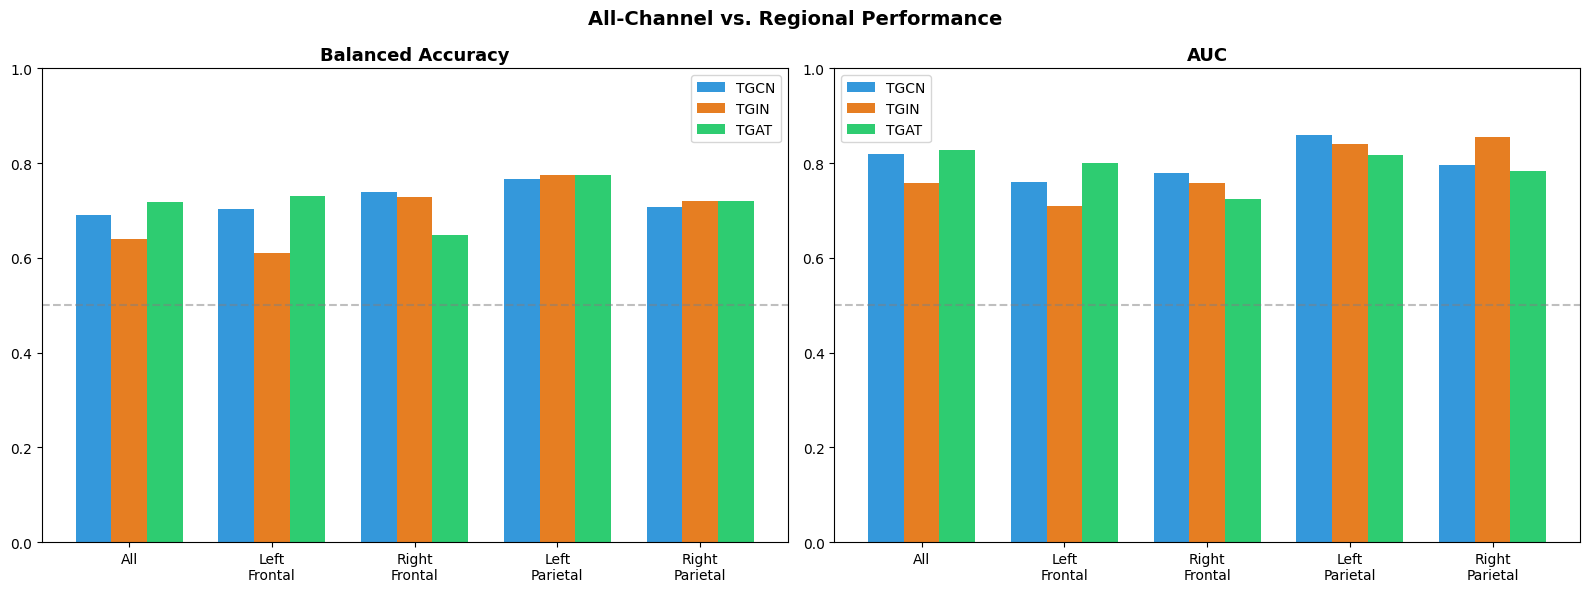

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
configs = ['All', 'Left_Frontal', 'Right_Frontal', 'Left_Parietal', 'Right_Parietal']
colors = {'TGCN': '#3498db', 'TGIN': '#e67e22', 'TGAT': '#2ecc71'}
x = np.arange(len(configs))
width = 0.25

for i, model_name in enumerate(MODEL_NAMES):
    bal_vals = [final_comparison[(final_comparison.region==c) & (final_comparison.model==model_name)]['balanced_accuracy'].values[0] for c in configs]
    auc_vals = [final_comparison[(final_comparison.region==c) & (final_comparison.model==model_name)]['auc'].values[0] for c in configs]
    axes[0].bar(x + (i-1)*width, bal_vals, width, label=model_name, color=colors[model_name])
    axes[1].bar(x + (i-1)*width, auc_vals, width, label=model_name, color=colors[model_name])

for ax, title in zip(axes, ['Balanced Accuracy', 'AUC']):
    ax.set_xticks(x); ax.set_xticklabels([c.replace('_','\n') for c in configs])
    ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(title, fontsize=13, fontweight='bold'); ax.legend(); ax.set_ylim(0, 1)

plt.suptitle('All-Channel vs. Regional Performance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'regional_comparison.png'), dpi=140, bbox_inches='tight')
plt.show()

# Cell 8 — Reload All-channel and regional test predictions

In [ ]:
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, accuracy_score
from statsmodels.stats.contingency_tables import mcnemar

ALL_RESULTS_DIR = RESULTS_DIR.parent / 'results'   # Notebook 7/9's original All-channel results
SPLIT_DIR_CHECK = PROJECT_ROOT / 'data' / 'split'

# --- Reload All-channel test data + run inference with the saved checkpoints ---
test_data_all = np.load(str(SPLIT_DIR_CHECK / 'test_data.npz'))
nf_all_test, adj_all_test, y_all_test = test_data_all['node_features'], test_data_all['adj'], test_data_all['y']
N_FEATURES_ALL = nf_all_test.shape[-1]

all_channel_probs_labels = {}
for model_name in MODEL_NAMES:
    model = build_model(model_name, N_FEATURES_ALL)
    state = torch.load(str(ALL_RESULTS_DIR / f'{model_name}_trained.pt'), map_location=DEVICE)
    model.load_state_dict(state)
    loader = DataLoader(EEGFeatureGraphDataset(nf_all_test, adj_all_test, y_all_test), batch_size=32)
    _, probs, labels = evaluate(model, loader)
    all_channel_probs_labels[model_name] = (probs, labels)
    del model
    gc.collect(); torch.cuda.empty_cache()

print(f'Reloaded All-channel test predictions for {list(all_channel_probs_labels.keys())}')

# --- Reload each region's test predictions the same way ---
regional_probs_labels = {}
for region in REGIONS:
    d = np.load(str(REGION_DIR / f'features_{region}.npz'), allow_pickle=True)
    node_features, adjacency, y_r, subjects_r = d['node_features'], d['adjacency'], d['y'], d['subjects']
    test_mask = np.isin(subjects_r, test_subj)
    n_features_r = node_features.shape[-1]

    for model_name in MODEL_NAMES:
        model = build_model(model_name, n_features_r)
        state = torch.load(str(RESULTS_DIR / f'{model_name}_{region}.pt'), map_location=DEVICE)
        model.load_state_dict(state)
        loader = DataLoader(EEGFeatureGraphDataset(node_features[test_mask], adjacency[test_mask], y_r[test_mask]),
                            batch_size=32)
        _, probs, labels = evaluate(model, loader)
        regional_probs_labels[(region, model_name)] = (probs, labels)
        del model
        gc.collect(); torch.cuda.empty_cache()

print(f'Reloaded regional test predictions for {len(regional_probs_labels)} region/model combinations')

# --- Verify window-level alignment across configs before any McNemar comparison ---
ref_labels = all_channel_probs_labels['TGCN'][1]
for region in REGIONS:
    region_labels = regional_probs_labels[(region, 'TGCN')][1]
    assert len(region_labels) == len(ref_labels), f'{region}: window count mismatch vs All!'
    assert (region_labels == ref_labels).all(), f'{region}: window order/labels do not match All — cannot compare directly!'
print('✓ All regions share identical window order and labels with the All-channel test set — safe to compare directly.')

Reloaded All-channel test predictions for ['TGCN', 'TGIN', 'TGAT']
Reloaded regional test predictions for 12 region/model combinations
✓ All regions share identical window order and labels with the All-channel test set — safe to compare directly.


# Cell 9 — Bootstrap 95% confidence intervals, All-channel and regional

In [ ]:
def bootstrap_ci(probs, labels, threshold=0.5, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(labels)
    bal_accs, aucs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        bp, bl = probs[idx], labels[idx]
        if len(np.unique(bl)) < 2:
            continue
        preds = (bp >= threshold).astype(int)
        bal_accs.append(balanced_accuracy_score(bl, preds))
        aucs.append(roc_auc_score(bl, bp))
    def summarize(vals):
        vals = np.array(vals)
        return np.mean(vals), np.percentile(vals, 2.5), np.percentile(vals, 97.5)
    return summarize(bal_accs), summarize(aucs)

print('=== Bootstrap 95% CI — All-Channel and Regional (window-level, n=627, 2000 resamples) ===\n')
ci_rows = []

for model_name in MODEL_NAMES:
    probs, labels = all_channel_probs_labels[model_name]
    (bal_m, bal_lo, bal_hi), (auc_m, auc_lo, auc_hi) = bootstrap_ci(probs, labels)
    print(f'All / {model_name}: BalAcc={bal_m:.3f} [{bal_lo:.3f}, {bal_hi:.3f}]   AUC={auc_m:.3f} [{auc_lo:.3f}, {auc_hi:.3f}]')
    ci_rows.append({'region': 'All', 'model': model_name, 'balacc_mean': bal_m, 'balacc_lo': bal_lo, 'balacc_hi': bal_hi,
                    'auc_mean': auc_m, 'auc_lo': auc_lo, 'auc_hi': auc_hi})

for region in REGIONS:
    for model_name in MODEL_NAMES:
        probs, labels = regional_probs_labels[(region, model_name)]
        (bal_m, bal_lo, bal_hi), (auc_m, auc_lo, auc_hi) = bootstrap_ci(probs, labels)
        print(f'{region} / {model_name}: BalAcc={bal_m:.3f} [{bal_lo:.3f}, {bal_hi:.3f}]   AUC={auc_m:.3f} [{auc_lo:.3f}, {auc_hi:.3f}]')
        ci_rows.append({'region': region, 'model': model_name, 'balacc_mean': bal_m, 'balacc_lo': bal_lo, 'balacc_hi': bal_hi,
                        'auc_mean': auc_m, 'auc_lo': auc_lo, 'auc_hi': auc_hi})

ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(str(RESULTS_DIR / 'regional_bootstrap_ci.csv'), index=False)
print(f'\nSaved → regional_bootstrap_ci.csv')

=== Bootstrap 95% CI — All-Channel and Regional (window-level, n=627, 2000 resamples) ===

All / TGCN: BalAcc=0.691 [0.652, 0.730]   AUC=0.820 [0.788, 0.851]
All / TGIN: BalAcc=0.639 [0.598, 0.680]   AUC=0.758 [0.720, 0.793]
All / TGAT: BalAcc=0.717 [0.679, 0.755]   AUC=0.828 [0.797, 0.857]
Left_Frontal / TGCN: BalAcc=0.703 [0.665, 0.739]   AUC=0.761 [0.723, 0.796]
Left_Frontal / TGIN: BalAcc=0.609 [0.569, 0.650]   AUC=0.709 [0.669, 0.746]
Left_Frontal / TGAT: BalAcc=0.730 [0.696, 0.763]   AUC=0.799 [0.765, 0.833]
Right_Frontal / TGCN: BalAcc=0.738 [0.704, 0.770]   AUC=0.778 [0.743, 0.812]
Right_Frontal / TGIN: BalAcc=0.728 [0.693, 0.761]   AUC=0.758 [0.721, 0.793]
Right_Frontal / TGAT: BalAcc=0.647 [0.608, 0.685]   AUC=0.724 [0.685, 0.762]
Left_Parietal / TGCN: BalAcc=0.766 [0.729, 0.800]   AUC=0.861 [0.832, 0.887]
Left_Parietal / TGIN: BalAcc=0.775 [0.741, 0.810]   AUC=0.841 [0.810, 0.870]
Left_Parietal / TGAT: BalAcc=0.776 [0.743, 0.808]   AUC=0.816 [0.783, 0.848]
Right_Parietal / T

# Cell 10 — McNemar's test: best region-model vs. best All-channel model

In [ ]:
print("=== McNemar's Test — Best Region-Model vs. Best All-Model (window-level, n=627) ===\n")

best_all_row = all_channel_df.loc[all_channel_df['balanced_accuracy'].idxmax()]
best_all_model = best_all_row['model']
all_probs, all_labels = all_channel_probs_labels[best_all_model]
all_preds = (all_probs >= 0.5).astype(int)
print(f'Best All-channel model: {best_all_model}  (BalAcc={best_all_row["balanced_accuracy"]:.3f})\n')

mcnemar_region_rows = []
for region in REGIONS:
    region_rows_df = final_comparison[final_comparison.region == region]
    best_region_model = region_rows_df.loc[region_rows_df['balanced_accuracy'].idxmax(), 'model']
    r_probs, r_labels = regional_probs_labels[(region, best_region_model)]
    r_preds = (r_probs >= 0.5).astype(int)

    correct_all = (all_preds == all_labels)
    correct_region = (r_preds == r_labels)
    table = [[np.sum(correct_all & correct_region), np.sum(correct_all & ~correct_region)],
            [np.sum(~correct_all & correct_region), np.sum(~correct_all & ~correct_region)]]
    result = mcnemar(table, exact=False, correction=True)
    significant = 'Yes' if result.pvalue < 0.05 else 'No'

    print(f'All ({best_all_model}) vs {region} ({best_region_model}): '
          f'statistic={result.statistic:.3f}  p-value={result.pvalue:.4f}  Significant (α=0.05): {significant}')
    mcnemar_region_rows.append({'Region': region, 'Region_best_model': best_region_model,
                                'All_best_model': best_all_model, 'Statistic': result.statistic,
                                'p-value': result.pvalue, 'Significant': significant})

mcnemar_region_df = pd.DataFrame(mcnemar_region_rows)
mcnemar_region_df.to_csv(str(RESULTS_DIR / 'regional_mcnemar_vs_all.csv'), index=False)
print(f'\nSaved → regional_mcnemar_vs_all.csv')

=== McNemar's Test — Best Region-Model vs. Best All-Model (window-level, n=627) ===

Best All-channel model: TGAT  (BalAcc=0.717)

All (TGAT) vs Left_Frontal (TGAT): statistic=3.062  p-value=0.0801  Significant (α=0.05): No
All (TGAT) vs Right_Frontal (TGCN): statistic=2.174  p-value=0.1403  Significant (α=0.05): No
All (TGAT) vs Left_Parietal (TGIN): statistic=2.507  p-value=0.1133  Significant (α=0.05): No
All (TGAT) vs Right_Parietal (TGIN): statistic=0.629  p-value=0.4277  Significant (α=0.05): No

Saved → regional_mcnemar_vs_all.csv
